# Week 3 — Detecting AI-generated essays on new topics

We keep Week 2’s majority-class baseline and train two text classifiers. The main question is how well they detect AI essays when the writing prompt is new.

## 1. Clean the data

Labels are `0` for human and `1` for AI. We standardize Unicode, case and spaces to identify duplicate essays and remove all copies before splitting. Models use the original essay text.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, GroupShuffleSplit, StratifiedGroupKFold
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline

SEED = 42
# Support running the notebook from the repository root or the notebooks folder.
data_path = Path("data/train_v2_drcat_02.csv")
if not data_path.is_file():
    data_path = Path("..") / data_path

raw = pd.read_csv(data_path, usecols=["text", "label", "prompt_name"])
print("Missing values:", raw.isna().sum().to_dict())

usable = raw.dropna().copy()
# Use normalized text to find duplicates. The models use the original essays.
normalized = (
    usable["text"].str.normalize("NFKC").str.casefold()
    .str.replace(r"\s+", " ", regex=True).str.strip()
)
# keep=False marks every copy of a duplicate essay.
duplicates = normalized.duplicated(keep=False)
data = usable.loc[normalized.ne("") & ~duplicates]
assert normalized.loc[data.index].is_unique
assert set(data["label"]) == {0, 1}

print(f"Raw essays: {len(raw):,}")
print(f"Duplicate rows removed: {duplicates.sum():,}")
print(f"Clean essays: {len(data):,} across {data['prompt_name'].nunique()} topics")
display(data["label"].map({0: "Human", 1: "AI"}).value_counts().rename("Essays"))

Missing values: {'text': 0, 'label': 0, 'prompt_name': 0}
Raw essays: 44,868
Duplicate rows removed: 12
Clean essays: 44,856 across 15 topics


label
Human    27359
AI       17497
Name: Essays, dtype: int64

## 2. Split by topic

A seeded split reserves three complete topics for the unseen-topic test. The familiar-topic test samples other essays with the same human and AI counts. The remaining essays are used for training.

In [2]:
# The dataset's prompt_name column groups all essays written for the same prompt.
holdout = GroupShuffleSplit(n_splits=1, test_size=3, random_state=SEED)
remaining_rows, unseen_rows = next(holdout.split(data, groups=data["prompt_name"]))
remaining = data.iloc[remaining_rows]
unseen = data.iloc[unseen_rows]

# Match class counts so both tests have the same proportions of human and AI essays.
class_counts = unseen["label"].value_counts().sort_index()
familiar = pd.concat([
    remaining.loc[remaining["label"] == label].sample(n=count, random_state=SEED)
    for label, count in class_counts.items()
]).sort_index()
train = remaining.drop(familiar.index)

train_topics = set(train["prompt_name"])
familiar_topics = set(familiar["prompt_name"])
unseen_topics = set(unseen["prompt_name"])

# Check topic isolation and confirm that each essay belongs to a single split.
assert len(unseen_topics) == 3
assert unseen_topics.isdisjoint(train_topics | familiar_topics)
assert familiar_topics <= train_topics
assert familiar["label"].value_counts().sort_index().equals(class_counts)
all_rows = set(train.index) | set(familiar.index) | set(unseen.index)
assert len(all_rows) == len(data) == len(train) + len(familiar) + len(unseen)

tests = {"Familiar topics": familiar, "Unseen topics": unseen}
splits = {"Training": train, **tests}
counts = pd.DataFrame.from_dict({
    name: {
        "Human": int(part["label"].eq(0).sum()),
        "AI": int(part["label"].eq(1).sum()),
        "Topics": part["prompt_name"].nunique(),
    }
    for name, part in splits.items()
}, orient="index")
display(counts)
print("Unseen topics:", ", ".join(sorted(unseen_topics)))

Unseen topics: "A Cowboy Who Rode the Waves", Grades for extracurricular activities, Phones and driving


,Human,AI,Topics
Training,19035,14639,12
Familiar topics,4162,1429,12
Unseen topics,4162,1429,3


## 3. Tune the text classifiers

`GridSearchCV` selects the settings with the highest AI-class F1 over three validation folds grouped by topic. TF-IDF is inside each pipeline, so it is fitted on the training essays of each fold.

In [3]:
# Give only essay text to the models and use prompt_name to define the folds.
X_train = train["text"]
y_train = train["label"]
groups = train["prompt_name"]
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)

# Check that each fold uses disjoint topics and has both classes on each side.
for train_rows, validation_rows in cv.split(X_train, y_train, groups):
    assert set(groups.iloc[train_rows]).isdisjoint(groups.iloc[validation_rows])
    assert y_train.iloc[train_rows].nunique() == 2
    assert y_train.iloc[validation_rows].nunique() == 2

# C controls logistic regression regularization. Alpha controls Naive Bayes smoothing.
settings = {
    "Logistic regression": (
        LogisticRegression(solver="liblinear", max_iter=1000, random_state=SEED),
        {"classifier__C": [0.1, 1.0, 4.0]},
    ),
    "Complement NB": (
        ComplementNB(),
        {"classifier__alpha": [0.1, 0.5, 1.0]},
    ),
}

tuned = {}
# Cache TF-IDF for repeated fits on the same fold.
with TemporaryDirectory(prefix="week3-tfidf-") as cache:
    for name, (classifier, grid) in settings.items():
        # Fit the TF-IDF vocabulary on the training essays of each fold.
        pipeline = Pipeline([
            ("tfidf", TfidfVectorizer(min_df=2, max_features=20_000)),
            ("classifier", classifier),
        ], memory=cache)
        search = GridSearchCV(pipeline, grid, scoring="f1", cv=cv, error_score="raise")
        search.fit(X_train, y_train, groups=groups)
        # Keep the fitted model ready to use after the temporary cache is deleted.
        tuned[name] = search.best_estimator_.set_params(memory=None)
        print(f"{name}: {search.best_params_}, validation F1 = {search.best_score_:.3f}")

Logistic regression: {'classifier__C': 4.0}, validation F1 = 0.874
Complement NB: {'classifier__alpha': 1.0}, validation F1 = 0.861


## 4. Combine the models

Soft voting averages the AI probabilities from the two tuned models.

In [4]:
# The dummy baseline always predicts the majority class.
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
# Refit the two tuned pipelines on the training set and average their probabilities.
voting = VotingClassifier(
    estimators=[
        ("logistic", tuned["Logistic regression"]),
        ("naive_bayes", tuned["Complement NB"]),
    ],
    voting="soft",
).fit(X_train, y_train)

models = {"Dummy": dummy, **tuned, "Soft voting": voting}

## 5. Evaluate on both tests

The human false-positive rate is the percentage of human essays incorrectly flagged as AI.

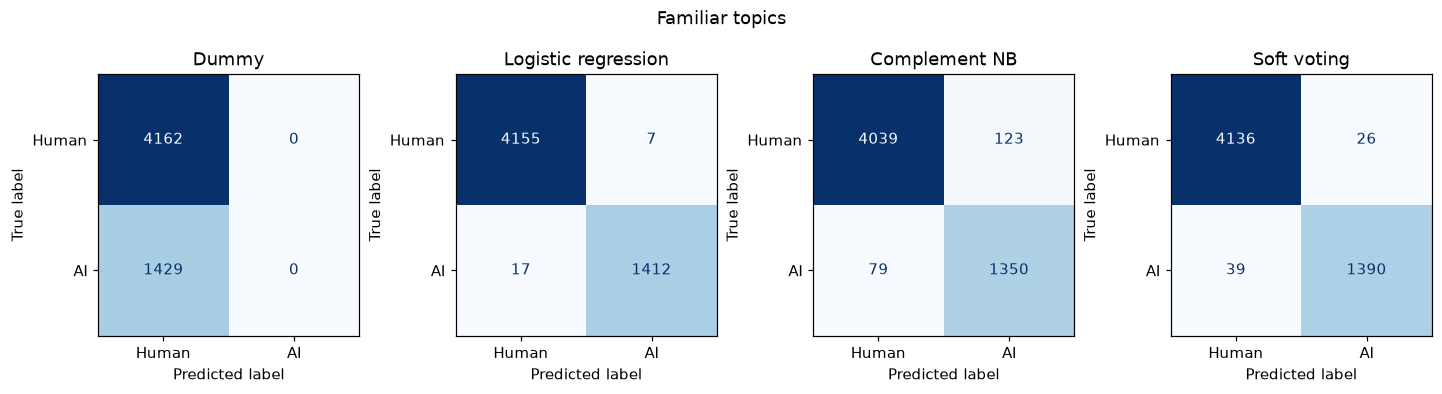

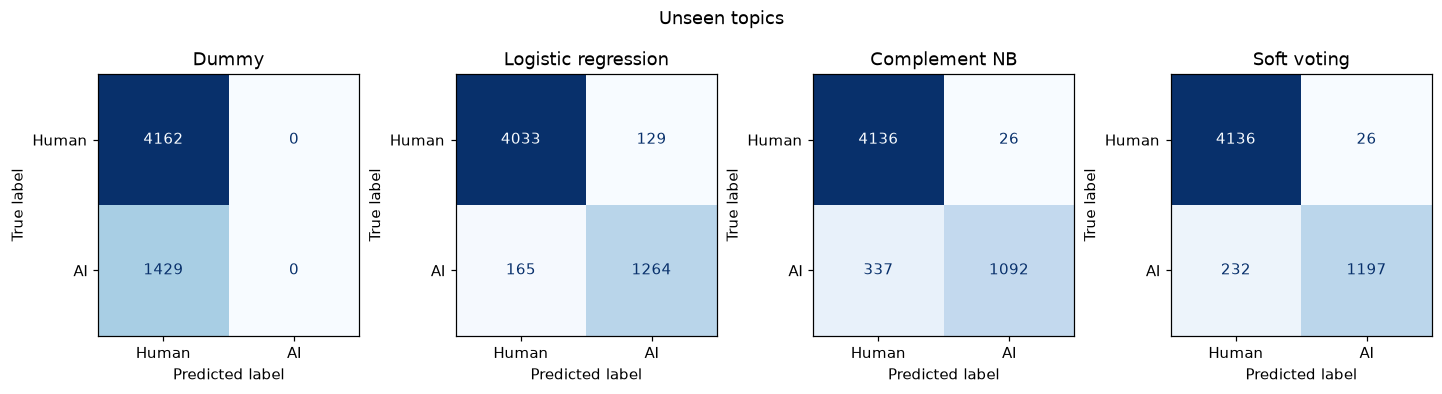

,Test,Model,Accuracy,F1 (AI),Human false positives (%)
0,Familiar topics,Dummy,0.744,0.000,0.000
1,Familiar topics,Logistic regression,0.996,0.992,0.168
2,Familiar topics,Complement NB,0.964,0.930,2.955
3,Familiar topics,Soft voting,0.988,0.977,0.625
4,Unseen topics,Dummy,0.744,0.000,0.000
5,Unseen topics,Logistic regression,0.947,0.896,3.099
6,Unseen topics,Complement NB,0.935,0.857,0.625
7,Unseen topics,Soft voting,0.954,0.903,0.625


In [5]:
# Evaluate the same fitted models on familiar and unseen topics.
rows = []
for test_name, test in tests.items():
    truth = test["label"]
    fig, axes = plt.subplots(1, len(models), figsize=(13, 3.5), layout="constrained")
    fig.suptitle(test_name)

    for ax, (name, model) in zip(axes, models.items()):
        predicted = model.predict(test["text"])
        matrix = ConfusionMatrixDisplay.from_predictions(
            truth, predicted, labels=[0, 1], display_labels=["Human", "AI"],
            cmap="Blues", colorbar=False, ax=ax,
        )
        ax.set_title(name)
        # Human essays are in the first row. FP counts the ones flagged as AI.
        tn, fp, fn, tp = matrix.confusion_matrix.ravel()
        rows.append({
            "Test": test_name,
            "Model": name,
            "Accuracy": accuracy_score(truth, predicted),
            "F1 (AI)": f1_score(truth, predicted),
            "Human false positives (%)": 100 * fp / (tn + fp),
        })
    plt.show()

results = pd.DataFrame(rows)
display(results.round(3))

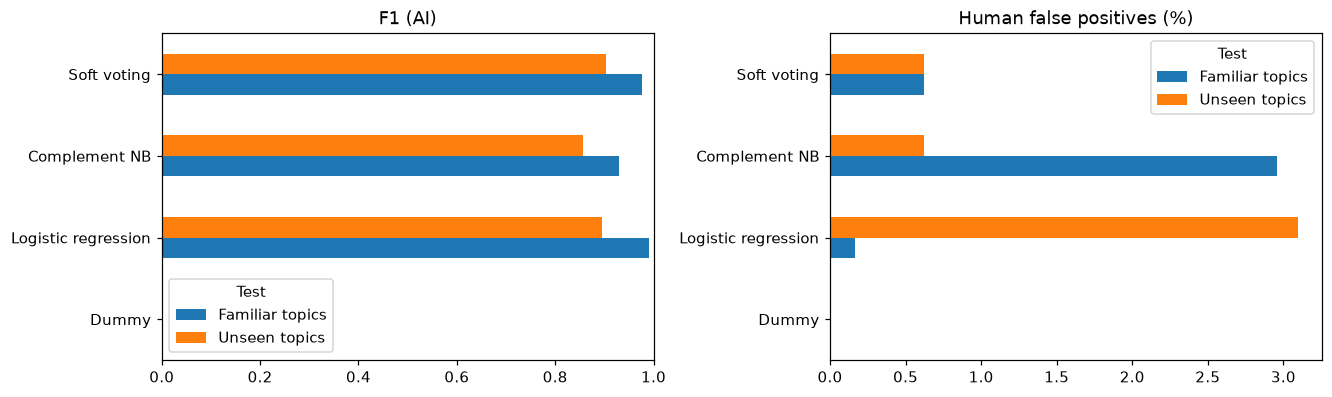

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
for ax, metric in zip(axes, ["F1 (AI)", "Human false positives (%)"]):
    # Put the two test scores side by side for each model.
    values = results.pivot(index="Model", columns="Test", values=metric).loc[list(models)]
    values.plot.barh(ax=ax, title=metric, ylabel="")
axes[0].set_xlim(0, 1)
plt.show()

## Results

Logistic regression's AI-class F1 drops from 0.992 on familiar topics to 0.896 on unseen topics. On unseen topics, soft voting reaches the highest F1 (0.903). Soft voting and Complement NB each flag 26 of 4,162 human essays (0.62%), compared with 129 for logistic regression (3.10%). These results describe the three held-out topics.